In [2]:
import pandas as pd

In [3]:
import geopandas as gpd
import osmnx as ox
import networkx as nx
import folium
import matplotlib.pyplot as plt

In [4]:
ox.geocode_to_gdf("Yeongdeungpo-gu,Seoul,South Korea")

,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"POLYGON ((126.87802 37.55296, 126.87804 37.551...",126.878024,37.484973,126.94993,37.556252,223075808,relation,2414781,37.5262,126.8959,boundary,administrative,12,0.525144,borough,Yeongdeungpo-gu,"Yeongdeungpo-gu, Seoul, South Korea"


In [5]:
ox.graph_from_place("Yeongdeungpo-gu, Seoul, South Korea")

In [6]:
# 1) 영등포구 전체 도로(자전거 필터 없이) 받기
G = ox.graph_from_place("Yeongdeungpo-gu, Seoul, South Korea")

In [7]:
print(len(G.nodes), len(G.edges))

6432 18085


In [8]:
# 1-1) 영등포구 전체 도로(자전거가 다닐수있는 도로) 받기
G_bike = ox.graph_from_place(
    "Yeongdeungpo-gu, Seoul, South Korea",
    network_type="bike"
)


In [9]:
print(len(G_bike.nodes), len(G_bike.edges))

4202 11014


In [10]:
# 1-2) 영등포구 자전거 전용도로 받기
G_cycleway = ox.graph_from_place(
    "Yeongdeungpo-gu, Seoul, South Korea",
    custom_filter='["highway"="cycleway"]'
)


In [11]:
print(len(G_cycleway.nodes), len(G_cycleway.edges))

39 69


In [12]:
# 1-3) 영등포구 애매한 자전거도로(일반도로에 자전거차선) 포함
G_cycle_all = ox.graph_from_place(
    "Yeongdeungpo-gu, Seoul, South Korea",
    custom_filter='["cycleway"]'
)


In [13]:
print(len(G_cycle_all.nodes), len(G_cycle_all.edges))

13 24


In [14]:
G_cycleway = ox.graph_from_place(
    "Yeongdeungpo-gu, Seoul, South Korea",
    custom_filter='["highway"="cycleway"]'
)
print(len(G_cycleway.nodes), len(G_cycleway.edges))

39 69


In [15]:
G_lane = ox.graph_from_place(
    "Yeongdeungpo-gu, Seoul, South Korea",
    custom_filter='["cycleway"]'
)
print(len(G_lane.nodes), len(G_lane.edges))

13 24


In [16]:
import networkx as nx

G_bike_infra = nx.compose(G_cycleway, G_lane)

print(len(G_bike_infra.nodes), len(G_bike_infra.edges))

52 93


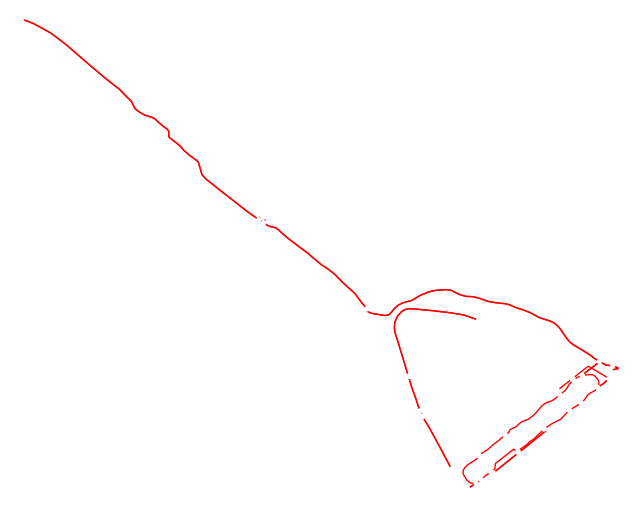

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [17]:
ox.plot_graph(G_bike_infra, node_size=15, edge_color="red", bgcolor="white")

In [18]:
import networkx as nx

G_undirected = G_bike_infra.to_undirected()
components = list(nx.connected_components(G_undirected))

print("덩어리 개수:", len(components))
for i, comp in enumerate(components):
    print(f"덩어리 {i+1}: 노드 {len(comp)}개")

덩어리 개수: 2
덩어리 1: 노드 39개
덩어리 2: 노드 13개


In [19]:
# 두 덩어리의 가장 가까운 지점 찾기
import itertools

# 두 덩어리를 따로 분리
comp_list = list(components)
comp1_nodes = comp_list[0]
comp2_nodes = comp_list[1]

# 각 덩어리의 노드 좌표 가져오기
def get_coords(nodes, G):
    return {n: (G.nodes[n]['y'], G.nodes[n]['x']) for n in nodes}

coords1 = get_coords(comp1_nodes, G_undirected)
coords2 = get_coords(comp2_nodes, G_undirected)

# 모든 쌍의 거리 계산해서 가장 가까운 쌍 찾기
from geopy.distance import distance

min_dist = float('inf')
closest_pair = None

for n1, c1 in coords1.items():
    for n2, c2 in coords2.items():
        d = distance(c1, c2).meters
        if d < min_dist:
            min_dist = d
            closest_pair = (n1, n2)

print("가장 가까운 노드 쌍:", closest_pair)
print("거리(미터):", round(min_dist, 1))

가장 가까운 노드 쌍: (5987527451, 13895055457)
거리(미터): 180.5


c:\Users\user\bike_network_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50672 (\N{HANGUL SYLLABLE YEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\bike_network_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\bike_network_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54596 (\N{HANGUL SYLLABLE PIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\bike_network_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\bike_network_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51648 (\N{H

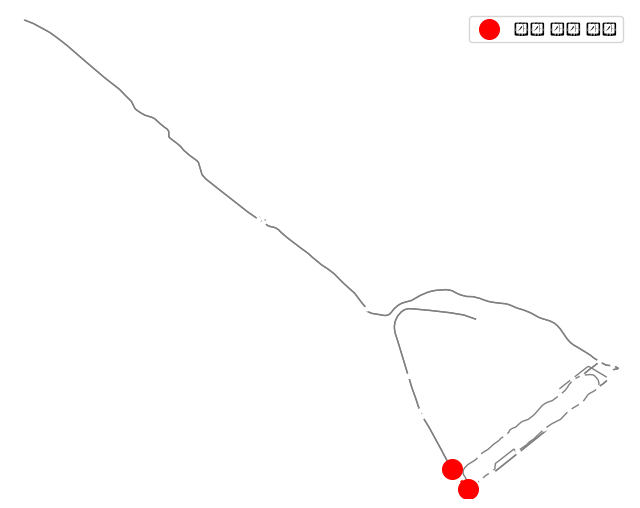

In [20]:
fig, ax = ox.plot_graph(
    G_bike_infra,
    node_size=15,
    edge_color="gray",
    bgcolor="white",
    show=False,
    close=False
)

n1, n2 = closest_pair
x1, y1 = G_undirected.nodes[n1]['x'], G_undirected.nodes[n1]['y']
x2, y2 = G_undirected.nodes[n2]['x'], G_undirected.nodes[n2]['y']

ax.scatter([x1, x2], [y1, y2], c="red", s=200, zorder=5, label="연결 필요 지점")
ax.plot([x1, x2], [y1, y2], c="red", linestyle="--", linewidth=2)
ax.legend()

import matplotlib.pyplot as plt
plt.show()

In [21]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 기본 한글 폰트
plt.rcParams['axes.unicode_minus'] = False

In [22]:
import pandas as pd

df_station = pd.read_csv("../data/station_master.csv", encoding="cp949")
df_station.head()

,대여소_ID,주소1,주소2,위도,경도
0,ST-999,서울특별시 양천구 목동서로 280,목동아파트 8단지 상가동,0.000000,0.000000
1,ST-998,서울특별시 양천구 목동서로 130,목동아파트 4단지 상가동,0.000000,0.000000
2,ST-997,서울특별시 양천구 목동중앙로 49,목동3단지 시내버스정류장,37.534390,126.869598
3,ST-996,서울특별시 양천구 남부순환로88길5-16,양강중학교앞 교차로,37.524334,126.850548
4,ST-995,서울특별시 양천구 중앙로 153 공중화장실,NaN,37.510597,126.857323


In [23]:
# 주소1에 '영등포구'가 들어간 행만 추출
df_ydp = df_station[df_station["주소1"].str.contains("영등포구", na=False)]

# 좌표가 0인 행(미입력) 제외
df_ydp = df_ydp[(df_ydp["위도"] != 0) & (df_ydp["경도"] != 0)]

print(df_ydp.shape)
df_ydp.head()

(207, 5)


,대여소_ID,주소1,주소2,위도,경도
297,ST-73,서울특별시 영등포구 여의동로 지하343,여의나루역 1번출구 앞,37.527157,126.931900
308,ST-72,서울특별시 영등포구 의사당대로 지하166,샛강역 1번출구 앞,37.517765,126.928413
319,ST-71,서울특별시 영등포구 의사당대로 166 샛강역,NaN,37.517586,126.929619
330,ST-70,서울특별시 영등포구 국제금융로 86,롯데캐슬 앞,37.520088,126.932365
342,ST-69,서울특별시 영등포구 국제금융로 106 행진빌딩,NaN,37.519131,126.933373


In [24]:
df_use = pd.read_csv("../data/20260909.csv", encoding="cp949", nrows=1000)
print(df_use.columns.tolist())
df_use.head()

['기준_날짜', '집계_기준', '기준_시간대', '시작_대여소_ID', '시작_대여소명', '종료_대여소_ID', '종료_대여소명', '전체_건수', '전체_이용_분', '전체_이용_거리']


,기준_날짜,집계_기준,기준_시간대,시작_대여소_ID,시작_대여소명,종료_대여소_ID,종료_대여소명,전체_건수,전체_이용_분,전체_이용_거리
0,20260909,출발시간,1005,ST-1660,자양3동_013_1,ST-1722,구의2동_049_1,1,13.0,2212.0
1,20260909,출발시간,1605,ST-1350,목5동_002_2,ST-1015,목5동_002_1,1,3.0,860.0
2,20260909,출발시간,735,ST-1015,목5동_002_1,ST-1350,목5동_002_2,1,3.0,778.0
3,20260909,출발시간,1610,ST-1344,한남동_030_1,ST-340,합정동_001_3,2,105.0,23869.0
4,20260909,출발시간,1800,ST-1179,대치1동_023_1,ST-1867,잠실3동_061_1,1,26.0,3869.0


In [25]:
# 영등포 구의 모든 대여소에서 몇 번 빌렸는지 정리

# 시작_대여소_ID별 하루 대여건수 합계
rent = df_use.groupby("시작_대여소_ID")["전체_건수"].sum().reset_index()
rent.columns = ["대여소_ID", "대여건수"]

# 영등포구 대여소(207개)와 합치기
df_ydp_use = df_ydp.merge(rent, on="대여소_ID", how="left")
print(df_ydp_use["대여건수"].isna().sum(), "개 대여소는 이용 기록 없음")
df_ydp_use.head()

136 개 대여소는 이용 기록 없음


,대여소_ID,주소1,주소2,위도,경도,대여건수
0,ST-73,서울특별시 영등포구 여의동로 지하343,여의나루역 1번출구 앞,37.527157,126.931900,NaN
1,ST-72,서울특별시 영등포구 의사당대로 지하166,샛강역 1번출구 앞,37.517765,126.928413,2.0
2,ST-71,서울특별시 영등포구 의사당대로 166 샛강역,NaN,37.517586,126.929619,1.0
3,ST-70,서울특별시 영등포구 국제금융로 86,롯데캐슬 앞,37.520088,126.932365,NaN
4,ST-69,서울특별시 영등포구 국제금융로 106 행진빌딩,NaN,37.519131,126.933373,NaN


In [26]:
# 136개 대여소는 이용 기록 없음 -> 207개 중 71개만 0909 대여 기록이 있음

In [27]:
import glob

# 202609로 시작하는 파일 병합
files = sorted(glob.glob("../data/202609*.csv"))
print(len(files), "개 파일")

df_all = pd.concat(
    [pd.read_csv(f, encoding="cp949") for f in files],
    ignore_index=True
)

# 날짜별 총 대여건수 (이상한 날 확인용)
print(df_all.groupby("기준_날짜")["전체_건수"].sum())

14 개 파일
기준_날짜
20260901     72858
20260902    280146
20260903    298956
20260904    318632
20260905    290238
20260906    266618
20260907    310376
20260908    318406
20260909    323722
20260910    321690
20260911    336028
20260912    291168
20260913    252336
20260914    322710
Name: 전체_건수, dtype: int64


In [28]:
# 영등포구 대여소만 남기기 + 대여소별 하루 평균 대여건수 (14일 전체)
ydp_ids = df_ydp["대여소_ID"]
df_ydp_use = df_all[df_all["시작_대여소_ID"].isin(ydp_ids)]

daily = df_ydp_use.groupby(["시작_대여소_ID", "기준_날짜"])["전체_건수"].sum().reset_index()
avg = daily.groupby("시작_대여소_ID")["전체_건수"].mean().reset_index()
avg.columns = ["대여소_ID", "일평균_대여건수"]

df_demand = df_ydp.merge(avg, on="대여소_ID", how="left")
print(df_demand["일평균_대여건수"].describe())
print("기록 없는 대여소:", df_demand["일평균_대여건수"].isna().sum())

count    174.000000
mean     155.660593
std      110.132863
min       11.692308
25%       74.285714
50%      132.071429
75%      212.678571
max      633.692308
Name: 일평균_대여건수, dtype: float64
기록 없는 대여소: 33


In [ ]:
# 대여소 일평균이 부풀려졌는지 점검 (0-7일이 있는지)

days = daily.groupby("시작_대여소_ID")["기준_날짜"].nunique()
print(days.describe())
print("7일 미만 대여소:", (days < 7).sum())

count    174.000000
mean      13.879310
std        0.495445
min        9.000000
25%       14.000000
50%       14.000000
75%       14.000000
max       14.000000
Name: 기준_날짜, dtype: float64
7일 미만 대여소: 0


In [30]:
df_age = pd.read_csv("../data/ydp_age_pop_2026-09.csv", encoding="cp949")